In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV,
    cross_val_predict
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from matplotlib.ticker import FuncFormatter

# Polski format liczb
def comma_formatter(x, pos):
    return f'{x:g}'.replace('.', ',')

formatter = FuncFormatter(comma_formatter)

In [3]:
ds1_df = pd.read_csv('../src/ds1_features.csv')
ds2_df = pd.read_csv('../src/ds2_features.csv')

CLASSES = ['N', 'S', 'V', 'F', 'Q']

metadata_columns = [
    'record_id',
    'annotation_sample',
    'type',
    'class',
    'anomaly',
    'lead'
]

feature_columns = [
    col for col in ds1_df.columns
    if col not in metadata_columns
]

X_train = ds1_df[feature_columns]
y_train = ds1_df['class']

X_test = ds2_df[feature_columns]
y_test = ds2_df['class']

In [4]:
groups = ds1_df['record_id'].replace({
    202: 201
})

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [5]:
cv_splits = list(
    cv.split(X_train, y_train, groups=groups)
)

assert len(cv_splits) == 5

In [6]:
svm_baseline = SkPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(
        score_func=f_classif,
        k='all'
    )),
    ('svm', SVC(
        kernel='rbf',
        cache_size=1000
    ))
])

In [7]:
baseline_grid = {
    'selector__k': [15, 'all'],
    'svm__C': [0.5, 1, 5, 10],
    'svm__gamma': ['scale', 0.01],
    'svm__class_weight': [None, 'balanced']
}

In [8]:
# grid_baseline = GridSearchCV(
#     estimator=svm_baseline,
#     param_grid=baseline_grid,
#     scoring='f1_macro',
#     cv=cv_splits,
#     n_jobs=1,
#     verbose=2,
#     refit=False,
#     return_train_score=False,
#     error_score='raise'
# )

# grid_baseline.fit(X_train, y_train)

In [9]:
# baseline_results = pd.DataFrame(grid_baseline.cv_results_)

# baseline_results.to_csv(
#     '../src/svm_baseline_cv_results.csv',
#     index=False
# )

# display(
#     baseline_results[[
#         'param_selector__k',
#         'param_svm__C',
#         'param_svm__gamma',
#         'param_svm__class_weight',
#         'mean_test_score',
#         'std_test_score',
#         'rank_test_score'
#     ]].sort_values('rank_test_score').head(10)
# )

# print('Najlepsze parametry:', grid_baseline.best_params_)
# print('Najlepszy macro F1:', grid_baseline.best_score_)

In [10]:
def smote_strategy(y):

    counts = pd.Series(y).value_counts()

    strategy = {}

    for cls in ['S', 'V', 'F', 'Q']:

        current = int(counts.get(cls, 0))

        if current < 2:
            continue

        target = min(
            current * 3,
            3000
        )

        if target > current:
            strategy[cls] = target

    return strategy

In [11]:
svm_smote = ImbPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(
        score_func=f_classif,
        k='all'
    )),
    ('smote', SMOTE(
        sampling_strategy=smote_strategy,
        random_state=42
    )),
    ('svm', SVC(
        kernel='rbf',
        class_weight=None,
        cache_size=1000
    ))
])

In [12]:
smote_grid = {
    'selector__k': [15, 'all'],
    'smote__k_neighbors': [3, 5],
    'svm__C': [1, 5],
    'svm__gamma': ['scale', 0.01]
}

In [13]:
# grid_smote = GridSearchCV(
#     estimator=svm_smote,
#     param_grid=smote_grid,
#     scoring='f1_macro',
#     cv=cv_splits,
#     n_jobs=1,
#     verbose=2,
#     refit=False,
#     return_train_score=False,
#     error_score='raise'
# )

# grid_smote.fit(X_train, y_train)

In [14]:
# smote_results = pd.DataFrame(grid_smote.cv_results_)

# smote_results.to_csv(
#     '../src/svm_smote_cv_results.csv',
#     index=False
# )

# display(
#     smote_results[[
#         'param_selector__k',
#         'param_smote__k_neighbors',
#         'param_svm__C',
#         'param_svm__gamma',
#         'mean_test_score',
#         'std_test_score',
#         'rank_test_score'
#     ]].sort_values('rank_test_score').head(10)
# )

# print('Najlepsze parametry:', grid_smote.best_params_)
# print('Najlepszy macro F1:', grid_smote.best_score_)

In [15]:
# comparison = pd.DataFrame({
#     'Model': ['SVM', 'SVM + SMOTE'],
#     'Macro F1': [
#         grid_baseline.best_score_,
#         grid_smote.best_score_
#     ],
#     'Std F1': [
#         grid_baseline.cv_results_['std_test_score'][
#             grid_baseline.best_index_
#         ],
#         grid_smote.cv_results_['std_test_score'][
#             grid_smote.best_index_
#         ]
#     ]
# })

# display(comparison.round(4))

In [16]:
# fold_comparison = pd.DataFrame({
#     'fold': range(1, 6),
#     'SVM': [
#         grid_baseline.cv_results_[f'split{i}_test_score'][
#             grid_baseline.best_index_
#         ]
#         for i in range(5)
#     ],
#     'SVM + SMOTE': [
#         grid_smote.cv_results_[f'split{i}_test_score'][
#             grid_smote.best_index_
#         ]
#         for i in range(5)
#     ]
# })

# display(fold_comparison.round(4))

In [17]:
final_svm = clone(svm_baseline)

final_svm.set_params(
    selector__k='all',
    svm__C=10,
    svm__gamma=0.01,
    svm__class_weight=None
)

final_svm.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['F','N','Q','S','V']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['mean','std','min',...,'rr_prev','rr_local_median','rr_prev_relative']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. Fo

In [21]:
y_pred_svm = final_svm.predict(X_test)

print(
    classification_report(
        y_test,
        y_pred_svm,
        labels=CLASSES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           N     0.8765    0.9472    0.9105     42425
           S     0.2284    0.0741    0.1119      1782
           V     0.7389    0.8442    0.7881      3422
           F     0.0084    0.0078    0.0080       387
           Q     0.0429    0.0134    0.0204      3886

    accuracy                         0.8335     51902
   macro avg     0.3790    0.3773    0.3678     51902
weighted avg     0.7763    0.8335    0.8016     51902



In [25]:
def evaluate_multiclass(y_true, y_pred, model_name):

    print(f'\n{model_name}')

    print(
        classification_report(
            y_true,
            y_pred,
            labels=CLASSES,
            digits=4,
            zero_division=0
        )
    )

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced accuracy': balanced_accuracy_score(
            y_true, y_pred
        ),
        'Macro precision': precision_score(
            y_true, y_pred,
            labels=CLASSES,
            average='macro',
            zero_division=0
        ),
        'Macro recall': recall_score(
            y_true, y_pred,
            labels=CLASSES,
            average='macro',
            zero_division=0
        ),
        'Macro F1': f1_score(
            y_true, y_pred,
            labels=CLASSES,
            average='macro',
            zero_division=0
        )
    }
    
def plot_confusion(y_true, y_pred, title):

    fig, ax = plt.subplots(figsize=(7, 6))

    disp = ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=CLASSES,
        display_labels=CLASSES,
        normalize='true',
        cmap='Blues',
        values_format='.2f',
        ax=ax
    )

    # Przecinki zamiast kropek w komórkach
    for label in disp.text_.ravel():
        label.set_text(
            label.get_text().replace('.', ',')
        )

    # Polski format liczb na pasku kolorów
    disp.im_.colorbar.ax.yaxis.set_major_formatter(formatter)

    ax.set_title(title)
    ax.set_xlabel('Klasa przewidziana')
    ax.set_ylabel('Klasa rzeczywista')

    plt.tight_layout()
    plt.show()

In [23]:
svm_metrics = evaluate_multiclass(
    y_test,
    y_pred_svm,
    'SVM — model końcowy'
)

display(pd.DataFrame([svm_metrics]).round(4))


SVM — model końcowy
              precision    recall  f1-score   support

           N     0.8765    0.9472    0.9105     42425
           S     0.2284    0.0741    0.1119      1782
           V     0.7389    0.8442    0.7881      3422
           F     0.0084    0.0078    0.0080       387
           Q     0.0429    0.0134    0.0204      3886

    accuracy                         0.8335     51902
   macro avg     0.3790    0.3773    0.3678     51902
weighted avg     0.7763    0.8335    0.8016     51902



,Model,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1
0,SVM — model końcowy,0.8335,0.3773,0.379,0.3773,0.3678


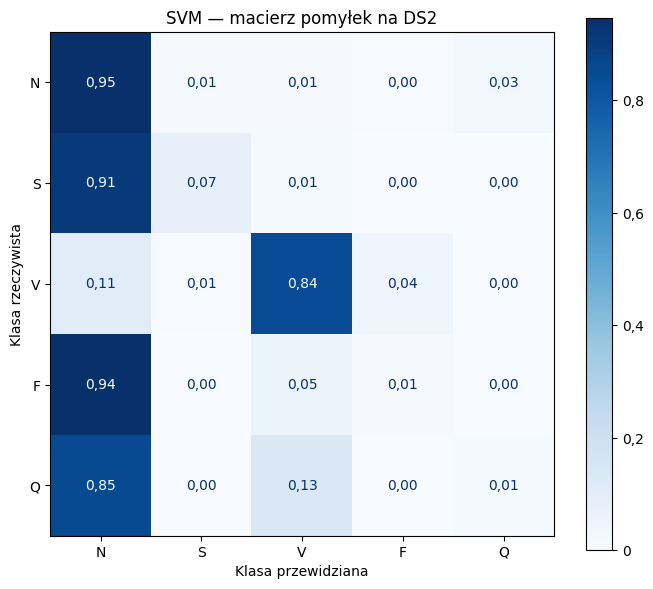

In [26]:
plot_confusion(
    y_test,
    y_pred_svm,
    'SVM — macierz pomyłek na DS2'
)

eksperyment

In [27]:
svm_balanced = clone(svm_baseline)

svm_balanced.set_params(
    selector__k='all',
    svm__C=1,
    svm__gamma='scale',
    svm__class_weight='balanced'
)

svm_balanced.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['F','N','Q','S','V']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['mean','std','min',...,'rr_prev','rr_local_median','rr_prev_relative']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. Fo

In [28]:
y_pred_balanced = svm_balanced.predict(X_test)

In [29]:
balanced_metrics = evaluate_multiclass(
    y_test,
    y_pred_balanced,
    'SVM balanced — DS2'
)

display(pd.DataFrame([balanced_metrics]).round(4))


SVM balanced — DS2
              precision    recall  f1-score   support

           N     0.9318    0.8127    0.8682     42425
           S     0.1969    0.1650    0.1795      1782
           V     0.4305    0.9062    0.5837      3422
           F     0.0025    0.0284    0.0046       387
           Q     0.0192    0.0090    0.0123      3886

    accuracy                         0.7306     51902
   macro avg     0.3162    0.3843    0.3297     51902
weighted avg     0.7983    0.7306    0.7553     51902



,Model,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1
0,SVM balanced — DS2,0.7306,0.3843,0.3162,0.3843,0.3297


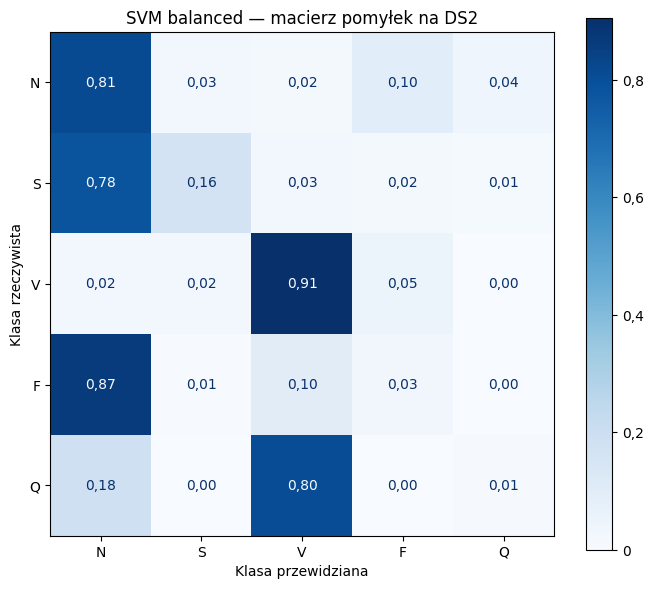

In [30]:
plot_confusion(
    y_test,
    y_pred_balanced,
    'SVM balanced — macierz pomyłek na DS2'
)

In [31]:
comparison = pd.DataFrame([
    svm_metrics,
    balanced_metrics
])

display(comparison.round(4))

,Model,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1
0,SVM — model końcowy,0.8335,0.3773,0.3790,0.3773,0.3678
1,SVM balanced — DS2,0.7306,0.3843,0.3162,0.3843,0.3297


In [32]:
recall_comparison = pd.DataFrame({
    'SVM': recall_score(
        y_test, y_pred_svm,
        labels=CLASSES,
        average=None,
        zero_division=0
    ),
    'SVM balanced': recall_score(
        y_test, y_pred_balanced,
        labels=CLASSES,
        average=None,
        zero_division=0
    )
}, index=CLASSES)

display(recall_comparison.round(4))

,SVM,SVM balanced
N,0.9472,0.8127
S,0.0741,0.1650
V,0.8442,0.9062
F,0.0078,0.0284
Q,0.0134,0.0090
